<a href="https://colab.research.google.com/github/claramanolache/DeepLearning/blob/main/CNN_mod2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install opendatasets
!pip install legacy-cgi

#Imports

In [2]:
import numpy as np

from sklearn import datasets
from sklearn import model_selection
from sklearn.metrics import accuracy_score
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

import torch
import torch.nn as nn
from torch.utils import data

import opendatasets as od
import pandas as pds

#Importing Dataset

In [3]:
od.download(
    "https://www.kaggle.com/datasets/ikjotsingh221/animal-dataset/data",force=True)

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: claramanolache
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/ikjotsingh221/animal-dataset


100%|██████████| 62.3M/62.3M [00:00<00:00, 89.2MB/s]


Checking to see what the dataset was downloaded as

In [4]:
import os

folder = "animal-dataset"

print(os.listdir(folder))


['dataset']


In [5]:
import os

train_dir = 'animal-dataset/dataset/Training'
test_dir = 'animal-dataset/dataset/Testing'

print(os.listdir(train_dir))
print(os.listdir(test_dir))

['crows', 'bears', 'elephants', 'rats']
['crows', 'bears', 'elephants', 'rats']


After I get labels from the images, I want to put all the images into one folder so you AI be able to see from file path where it is

In [6]:
from pathlib import Path
subfolder_path = Path("animal-dataset/dataset") / "all_labels"
subfolder_path.mkdir(parents=True, exist_ok=True)
print(f"Subfolder created at: {subfolder_path}")

Subfolder created at: animal-dataset/dataset/all_labels


get labels from root directory and rename. I also want to combine test and train to randomize the division in later step (can't trust how creator seperated)

In [7]:
import uuid
from pathlib import Path
import shutil
import pandas as pd

# target subdirectory for moved files
subfolder_path = Path("animal-dataset/dataset/all_labels")
subfolder_path.mkdir(parents=True, exist_ok=True)

# initialize
df = pd.DataFrame(columns=['file_path', 'label'])

def mover_renamer(directory):
    global df
    new_rows = []
    dir_path = Path(directory)

    label_name = dir_path.name

    for file in dir_path.iterdir():
        if file.is_file():
            extension = file.suffix
            new_filename = f"{uuid.uuid4().hex}{extension}"
            new_path = subfolder_path / new_filename

            shutil.move(str(file), str(new_path))

            new_rows.append({
                'file_path': str(new_path),
                'label': label_name
            })

    if new_rows:
        df = pd.concat([df, pd.DataFrame(new_rows)], ignore_index=True)

# testing with crows:
mover_renamer("animal-dataset/dataset/Training/crows")
display(df.head())


,file_path,label
0,animal-dataset/dataset/all_labels/dc1220e62e9d...,crows
1,animal-dataset/dataset/all_labels/f3a4f9331750...,crows
2,animal-dataset/dataset/all_labels/c686b5345e10...,crows
3,animal-dataset/dataset/all_labels/9be8d464309e...,crows
4,animal-dataset/dataset/all_labels/d1cd22186f8c...,crows


In [8]:
df.shape

(231, 2)

now that I know crows works, I am going to do the rest of the files


In [9]:
mover_renamer("animal-dataset/dataset/Training/bears")
mover_renamer("animal-dataset/dataset/Training/rats")
mover_renamer("animal-dataset/dataset/Training/elephants")
mover_renamer("animal-dataset/dataset/Testing/crows")
mover_renamer("animal-dataset/dataset/Testing/bears")
mover_renamer("animal-dataset/dataset/Testing/rats")
mover_renamer("animal-dataset/dataset/Testing/elephants")

In [10]:
# should be 1564 files
df.shape

(1564, 2)

# Building CNN

## test, training, and validation set

In [11]:
random_seed = 42

In [12]:
# Extract image paths as X and labels as y
X = df['file_path']  # image paths
y = df['label']      # labels

# Display their shapes and y
print(f"X shape: {X.shape}, y shape: {y.shape}")
display(y.head())

X shape: (1564,), y shape: (1564,)


,label
0,crows
1,crows
2,crows
3,crows
4,crows


In [13]:
from sklearn.model_selection import train_test_split

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=random_seed, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=random_seed, stratify=y_train_full
)

print(f"Training set: {X_train.shape[0]}")
print(f"Validation set: {X_val.shape[0]}")
print(f"Testing set: {X_test.shape[0]}")

Training set: 1000
Validation set: 251
Testing set: 313


##Preproccessing

want to experient with grey scale vs non grey scale, in latter step will compare effeectivity

In [14]:
import PIL.Image
from pathlib import Path

def convert_to_grayscale(path_str):
    path = Path(path_str)
    # new filename with _gs appended before the extension
    new_filename = f"{path.stem}_gs{path.suffix}"
    new_path = path.parent / new_filename

    # Open, convert to grayscale, and save
    if not new_path.exists():
        with PIL.Image.open(path) as img:
            gs_img = img.convert("L")
            gs_img.save(new_path)

    return str(new_path)

X_train_gs = X_train.apply(convert_to_grayscale)
X_val_gs = X_val.apply(convert_to_grayscale)
X_test_gs = X_test.apply(convert_to_grayscale)


##Structures
* small_model
* small_model_rgb
* model
* large_model

small model

In [18]:
import torch.nn as nn

small_model = nn.Sequential(
    nn.Conv2d(in_channels=1, out_channels=8,kernel_size=3, stride=1, padding=1),
    nn.ReLU(),

    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Conv2d(in_channels=8, out_channels=16,kernel_size=3, stride=1, padding=1),
    nn.ReLU(),

    nn.MaxPool2d(kernel_size=2, stride=2),

    # Output: 16 channels x 32 x 32
    nn.Flatten(),

    # Fully Connected Layers
    nn.Linear(16 * 32 * 32, 64),
    nn.ReLU(),

    nn.Linear(64, 4)
)

In [ ]:
try:
    from torchinfo import summary
except ImportError:
    !pip install torchinfo
    from torchinfo import summary

summary(small_model, input_size=(1, 1, 128, 128))

small model rgb (same size, just accepts 3 chanells )

In [36]:
small_model_rgb = nn.Sequential(
    nn.Conv2d(in_channels=3, out_channels=8,
              kernel_size=3, stride=1, padding=1),
    nn.ReLU(),

    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Conv2d(in_channels=8, out_channels=16,
              kernel_size=3, stride=1, padding=1),
    nn.ReLU(),

    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Flatten(),

    nn.Linear(16 * 32 * 32, 64),
    nn.ReLU(),

    nn.Linear(64, 4)
)

normal model

In [19]:
import torch.nn as nn

model = nn.Sequential(
    nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2), # Output size: 32 channels x 64 x 64

    # Flattening for linear layers
    nn.Flatten(), # 32 * 64 * 64 = 131,072

    # Fully Connected Blocks
    nn.Linear(32 * 64 * 64, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 4) # 4 classes: crows, bears, rats, elephants
)

In [ ]:
try:
    from torchinfo import summary
except ImportError:
    !pip install torchinfo
    from torchinfo import summary

summary(model, input_size=(1, 1, 128, 128))

large model

In [20]:
import torch.nn as nn

large_model = nn.Sequential(
    nn.Conv2d(in_channels=1, out_channels=32,
              kernel_size=3, stride=1, padding=1),
    nn.ReLU(),

    nn.Conv2d(in_channels=32, out_channels=64,
              kernel_size=3, stride=1, padding=1),
    nn.ReLU(),

    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Conv2d(in_channels=64, out_channels=128,
              kernel_size=3, stride=1, padding=1),
    nn.ReLU(),

    nn.Conv2d(in_channels=128, out_channels=256,
              kernel_size=3, stride=1, padding=1),
    nn.ReLU(),

    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.MaxPool2d(kernel_size=2, stride=2),

    # Output: 256 channels x 16 x 16
    nn.Flatten(),

    # Fully Connected Layers
    nn.Linear(256 * 16 * 16, 256),
    nn.ReLU(),

    nn.Linear(256, 128),
    nn.ReLU(),

    nn.Linear(128, 4)
)

In [ ]:
try:
    from torchinfo import summary
except ImportError:
    !pip install torchinfo
    from torchinfo import summary

summary(large_model, input_size=(1, 1, 128, 128))

##Hyperparameters
* learning_rate
* batch_size
* num_epochs
* patience
* weight_decay


In [26]:
import torch
import torch.optim as optim

# Training Hyperparameters
learning_rate = 0.001
batch_size = 32
num_epochs = 50
patience = 5
weight_decay = 1e-4

# Loss Function
criterion = nn.CrossEntropyLoss()

optimizers

In [24]:
small_optimizer = optim.Adam(
    small_model.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay
)

In [38]:
small_rgb_optimizer = optim.Adam(
    small_model_rgb.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay
)

In [ ]:
optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay
)

In [25]:
large_optimizer = optim.Adam(
    large_model.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay
)

## Training Different Models
* small
* normal model
* RGB (comparing with small)

#### data loaders

In [42]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Label encoding
label_to_idx = {
    "crows": 0,
    "bears": 1,
    "rats": 2,
    "elephants": 3
}

# Custom dataset for grayscale and RGB
class AnimalDataset(Dataset):
    def __init__(self, paths, labels, transform, mode="L"):
        self.paths = list(paths)
        self.labels = list(labels)
        self.transform = transform
        self.mode = mode

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        with Image.open(self.paths[idx]) as img:
            image = img.convert(self.mode)

        image = self.transform(image)
        label = int(self.labels[idx])

        return image, label


# Grayscale transformation
val_transforms = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Grayscale training and validation
train_dataset = AnimalDataset(
    X_train_gs,
    y_train.map(label_to_idx),
    val_transforms,
    mode="L"
)

val_dataset = AnimalDataset(
    X_val_gs,
    y_val.map(label_to_idx),
    val_transforms,
    mode="L"
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

#### Training

##### model

In [23]:
best_val_loss = float("inf")
epochs_without_improvement = 0

for epoch in range(num_epochs):

    # TRAINING
    model.train()

    for images, labels in train_loader:
        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

    # VALIDATION
    model.eval()
    total_val_loss = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in val_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)

            total_val_loss += loss.item() * images.size(0)
            total_samples += images.size(0)

    avg_val_loss = total_val_loss / total_samples

    print(f"Epoch {epoch+1}: Val Loss = {avg_val_loss:.4f}")

    # EARLY STOPPING
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        epochs_without_improvement = 0
        torch.save(model.state_dict(), "best_model.pth")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping triggered")
        break

# Restore best model
model.load_state_dict(torch.load("best_model.pth", weights_only=True))

Epoch 1: Val Loss = 1.0876
Epoch 2: Val Loss = 1.0326
Epoch 3: Val Loss = 0.6024
Epoch 4: Val Loss = 0.5726
Epoch 5: Val Loss = 0.4910
Epoch 6: Val Loss = 0.5704
Epoch 7: Val Loss = 0.6914
Epoch 8: Val Loss = 0.6110
Epoch 9: Val Loss = 0.6105
Epoch 10: Val Loss = 0.6181
Early stopping triggered


<All keys matched successfully>

##### small model

In [27]:
import torch
import torch.optim as optim

best_val_loss = float("inf")
epochs_without_improvement = 0

for epoch in range(num_epochs):

    # TRAINING
    small_model.train()

    for images, labels in train_loader:
        small_optimizer.zero_grad()

        outputs = small_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        small_optimizer.step()

    # VALIDATION
    small_model.eval()
    total_val_loss = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in val_loader:
            outputs = small_model(images)
            loss = criterion(outputs, labels)

            total_val_loss += loss.item() * images.size(0)
            total_samples += images.size(0)

    avg_val_loss = total_val_loss / total_samples

    print(f"Epoch {epoch+1}: Val Loss = {avg_val_loss:.4f}")

    # EARLY STOPPING
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        epochs_without_improvement = 0

        torch.save(
            small_model.state_dict(),
            "best_small_model.pth"
        )
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping triggered")
        break

# Restore best small model
small_model.load_state_dict(
    torch.load("best_small_model.pth", weights_only=True)
)

Epoch 1: Val Loss = 1.0307
Epoch 2: Val Loss = 0.8820
Epoch 3: Val Loss = 0.7053
Epoch 4: Val Loss = 0.6948
Epoch 5: Val Loss = 0.5184
Epoch 6: Val Loss = 0.5066
Epoch 7: Val Loss = 0.5245
Epoch 8: Val Loss = 0.5612
Epoch 9: Val Loss = 0.5497
Epoch 10: Val Loss = 0.5049
Epoch 11: Val Loss = 0.5653
Epoch 12: Val Loss = 0.6213
Epoch 13: Val Loss = 0.5872
Epoch 14: Val Loss = 0.5105
Epoch 15: Val Loss = 0.5592
Early stopping triggered


<All keys matched successfully>

##### small rgb

In [ ]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

class RGBAnimalDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = list(paths)
        self.labels = list(labels)
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        image = Image.open(self.paths[idx]).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, int(self.labels[idx])


rgb_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

train_rgb_dataset = RGBAnimalDataset(
    X_train,
    y_train.map(label_to_idx),
    rgb_transform
)

val_rgb_dataset = RGBAnimalDataset(
    X_val,
    y_val.map(label_to_idx),
    rgb_transform
)

train_rgb_loader = DataLoader(
    train_rgb_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_rgb_loader = DataLoader(
    val_rgb_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [43]:
best_val_loss = float("inf")
epochs_without_improvement = 0

rgb_train_losses = []
rgb_val_losses = []
rgb_train_accs = []
rgb_val_accs = []

for epoch in range(num_epochs):

    # TRAINING
    small_model_rgb.train()

    running_loss = 0
    correct_train = 0
    total_train = 0

    for images, labels in train_rgb_loader:
        small_rgb_optimizer.zero_grad()

        outputs = small_model_rgb(images)
        loss = criterion(outputs, labels)

        loss.backward()
        small_rgb_optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct_train += (outputs.argmax(1) == labels).sum().item()
        total_train += labels.size(0)

    avg_train_loss = running_loss / total_train
    train_accuracy = correct_train / total_train

    # VALIDATION
    small_model_rgb.eval()

    total_val_loss = 0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_rgb_loader:

            outputs = small_model_rgb(images)
            loss = criterion(outputs, labels)

            total_val_loss += loss.item() * images.size(0)
            correct_val += (outputs.argmax(1) == labels).sum().item()
            total_val += labels.size(0)

    avg_val_loss = total_val_loss / total_val
    val_accuracy = correct_val / total_val

    # Store metrics
    rgb_train_losses.append(avg_train_loss)
    rgb_val_losses.append(avg_val_loss)
    rgb_train_accs.append(train_accuracy)
    rgb_val_accs.append(val_accuracy)

    print(
        f"Epoch {epoch+1}: "
        f"Train Loss={avg_train_loss:.4f}, "
        f"Train Acc={train_accuracy:.2%}, "
        f"Val Loss={avg_val_loss:.4f}, "
        f"Val Acc={val_accuracy:.2%}"
    )

    # EARLY STOPPING
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        epochs_without_improvement = 0

        torch.save(
            small_model_rgb.state_dict(),
            "best_small_rgb_model.pth"
        )
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping triggered")
        break

# Restore best RGB weights
small_model_rgb.load_state_dict(
    torch.load("best_small_rgb_model.pth", weights_only=True)
)

Epoch 1: Train Loss=1.1891, Train Acc=47.30%, Val Loss=1.0905, Val Acc=52.99%
Epoch 2: Train Loss=0.8224, Train Acc=69.10%, Val Loss=0.8395, Val Acc=65.74%
Epoch 3: Train Loss=0.6167, Train Acc=77.60%, Val Loss=0.6993, Val Acc=73.71%
Epoch 4: Train Loss=0.4160, Train Acc=86.20%, Val Loss=0.6131, Val Acc=74.50%
Epoch 5: Train Loss=0.2629, Train Acc=91.50%, Val Loss=0.4888, Val Acc=82.47%
Epoch 6: Train Loss=0.2477, Train Acc=91.80%, Val Loss=0.5585, Val Acc=80.88%
Epoch 7: Train Loss=0.1328, Train Acc=95.90%, Val Loss=0.5847, Val Acc=84.86%
Epoch 8: Train Loss=0.1078, Train Acc=97.10%, Val Loss=0.4082, Val Acc=90.84%
Epoch 9: Train Loss=0.0571, Train Acc=98.60%, Val Loss=0.4147, Val Acc=90.04%
Epoch 10: Train Loss=0.0515, Train Acc=99.00%, Val Loss=0.4670, Val Acc=88.45%
Epoch 11: Train Loss=0.0694, Train Acc=98.50%, Val Loss=0.4150, Val Acc=88.84%
Epoch 12: Train Loss=0.0305, Train Acc=99.50%, Val Loss=0.4038, Val Acc=90.84%
Epoch 13: Train Loss=0.0238, Train Acc=99.70%, Val Loss=0.451

<All keys matched successfully>

#### Evaluations

In [28]:
from torch.utils.data import DataLoader

# Convert test labels to numerical values
y_test_idx = y_test.map(label_to_idx).values

# Create test dataset
test_dataset = AnimalDataset(
    X_test_gs,
    y_test_idx,
    transform=val_transforms
)

# Create test loader
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

##### on small

evaluating on test

In [30]:
import torch

# Load best saved small CNN
small_model.load_state_dict(
    torch.load("best_small_model.pth", weights_only=True)
)

small_model.eval()

test_loss = 0.0
correct = 0
total = 0

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:

        outputs = small_model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Calculate final metrics
test_loss /= total
test_accuracy = correct / total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.6045
Test Accuracy: 89.14%


confusion matrix

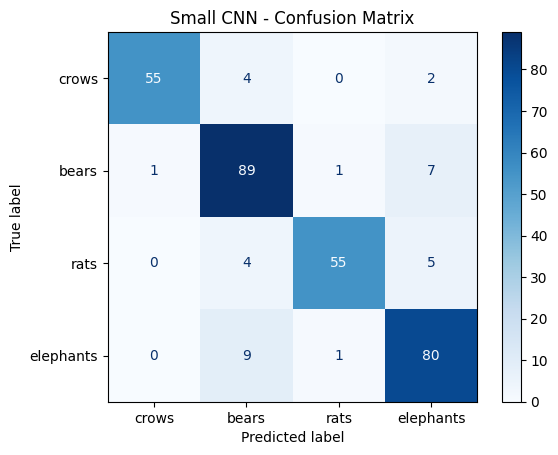

In [31]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_names = [
    name for name, idx in
    sorted(label_to_idx.items(), key=lambda x: x[1])
]

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=range(len(class_names))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues")
plt.title("Small CNN - Confusion Matrix")
plt.show()

precision, recall, and F1-score

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    all_labels,
    all_predictions,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

##### on large

In [32]:
import torch

# Load best saved CNN
model.load_state_dict(
    torch.load("best_model.pth", weights_only=True)
)

model.eval()

test_loss = 0.0
correct = 0
total = 0

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Calculate final metrics
test_loss /= total
test_accuracy = correct / total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.5109
Test Accuracy: 86.90%


confusion matrix

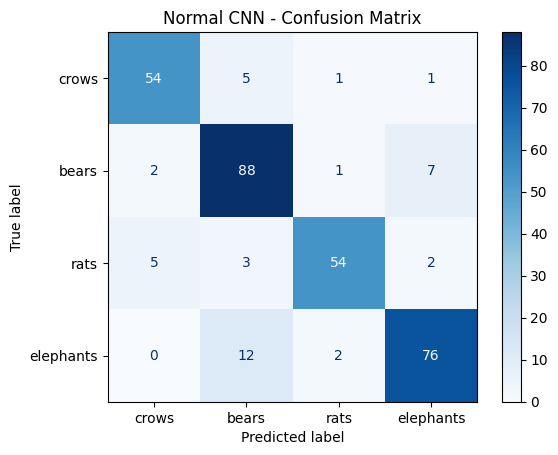

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_names = [
    name for name, idx in
    sorted(label_to_idx.items(), key=lambda x: x[1])
]

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=range(len(class_names))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues")
plt.title("Normal CNN - Confusion Matrix")
plt.show()

precision, recall, and F1-score

In [34]:
from sklearn.metrics import classification_report

print(classification_report(
    all_labels,
    all_predictions,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

       crows       0.89      0.89      0.89        61
       bears       0.81      0.90      0.85        98
        rats       0.93      0.84      0.89        64
   elephants       0.88      0.84      0.86        90

    accuracy                           0.87       313
   macro avg       0.88      0.87      0.87       313
weighted avg       0.87      0.87      0.87       313



##### on rgb

In [44]:
# Convert test labels to numerical values
y_test_idx = y_test.map(label_to_idx).values

# Create RGB test dataset
test_rgb_dataset = RGBAnimalDataset(
    X_test,
    y_test_idx,
    transform=rgb_transform
)

# Create RGB test loader
test_rgb_loader = DataLoader(
    test_rgb_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [45]:
import torch

# Load best saved RGB CNN
small_model_rgb.load_state_dict(
    torch.load("best_small_rgb_model.pth", weights_only=True)
)

small_model_rgb.eval()

test_loss_rgb = 0.0
correct_rgb = 0
total_rgb = 0

all_predictions_rgb = []
all_labels_rgb = []

with torch.no_grad():
    for images, labels in test_rgb_loader:

        outputs = small_model_rgb(images)
        loss = criterion(outputs, labels)

        test_loss_rgb += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total_rgb += labels.size(0)
        correct_rgb += (predicted == labels).sum().item()

        all_predictions_rgb.extend(predicted.cpu().numpy())
        all_labels_rgb.extend(labels.cpu().numpy())

# Calculate final metrics
test_loss_rgb /= total_rgb
test_accuracy_rgb = correct_rgb / total_rgb

print(f"RGB Test Loss: {test_loss_rgb:.4f}")
print(f"RGB Test Accuracy: {test_accuracy_rgb * 100:.2f}%")

RGB Test Loss: 0.4044
RGB Test Accuracy: 90.10%


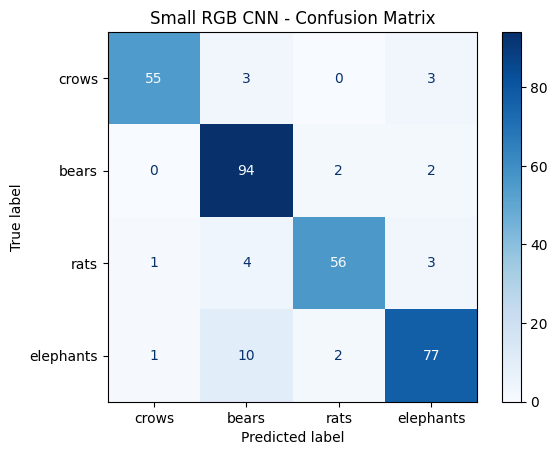

In [47]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_names = [
    name for name, idx in
    sorted(label_to_idx.items(), key=lambda x: x[1])
]

cm_rgb = confusion_matrix(
    all_labels_rgb,
    all_predictions_rgb,
    labels=range(len(class_names))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rgb,
    display_labels=class_names
)

disp.plot(cmap="Blues")
plt.title("Small RGB CNN - Confusion Matrix")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    all_labels_rgb,
    all_predictions_rgb,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

##### comparing

In [48]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Small Grayscale CNN", "Small RGB CNN"],
    "Test Accuracy": [
        test_accuracy,
        test_accuracy_rgb
    ],
    "Test Loss": [
        test_loss,
        test_loss_rgb
    ]
})

display(comparison)

,Model,Test Accuracy,Test Loss
0,Small Grayscale CNN,0.869010,0.510934
1,Small RGB CNN,0.900958,0.404374
